# 01 · Exploratory analysis

**Case study 7: cutting unplanned downtime on a machine fleet** · Phase 4b, notebook 1 of 3

This notebook charts the SQL results for **Q1** (where failures concentrate) and **Q2** (how reliable each group is), then looks at the sensor readings to prepare **Q3**: does anything change before a machine fails?

Inputs: `data/exports/*.csv` (written by `src/export_views.py`) and the raw telemetry in `data/raw/`. Outputs: charts in `images/`.

> The dataset is synthetic. Findings show what this method would reveal on real plant data.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> repo root/src
import pdm
from pdm import INK, INK_2, MUTED, AXIS, SERIES, SENSORS, SENSOR_LABEL, COMPONENTS

pdm.set_style()
pd.set_option("display.width", 120)

## 1. Where do failures concentrate? (Q1)

### By component

Component failures are counted one per failed part (761 in 2015), because each is a part to replace.

In [2]:
comp = pdm.load_export("v_pareto_component")
comp

,comp,failures,pct_of_failures,cum_pct,pareto_rank
0,comp2,259,34.0,34.0,1
1,comp1,192,25.2,59.3,2
2,comp4,179,23.5,82.8,3
3,comp3,131,17.2,100.0,4


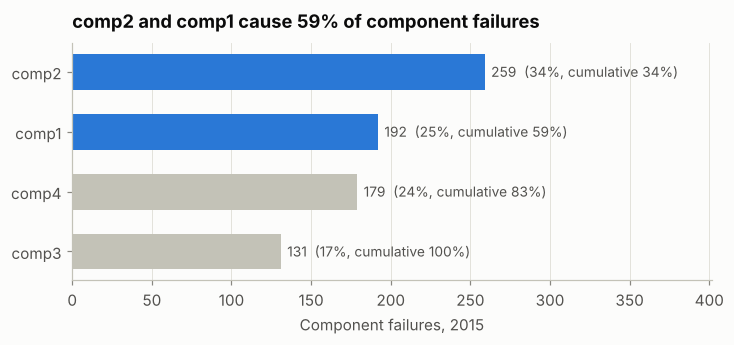

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
c = comp.sort_values("failures")
colors = [SERIES[0] if r <= 2 else AXIS for r in c["pareto_rank"]]
ax.barh(c["comp"], c["failures"], color=colors, height=0.6)
for y, (n, pct, cum) in enumerate(zip(c["failures"], c["pct_of_failures"], c["cum_pct"])):
    ax.text(n + 4, y, f"{n}  ({pct:.0f}%, cumulative {cum:.0f}%)", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, c["failures"].max() * 1.55)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Component failures, 2015")
ax.set_title("comp2 and comp1 cause 59% of component failures")
pdm.save(fig, "q1_pareto_component.png")
plt.show()

### By machine model and age

Models and age groups are counted in **failure events** (719): one event is one stoppage, even when two parts failed together. Raw counts by model mostly reflect how many machines each model has, so the fair comparison is **failures per machine**.

In [4]:
model = pdm.load_export("v_pareto_model")
model[["model", "machines", "avg_age", "failure_events", "events_per_machine", "pct_of_fleet", "pct_of_events"]]

,model,machines,avg_age,failure_events,events_per_machine,pct_of_fleet,pct_of_events
0,model3,35,12.0,212,6.06,35.0,29.5
1,model1,16,12.3,175,10.94,16.0,24.3
2,model4,32,9.3,172,5.38,32.0,23.9
3,model2,17,12.8,160,9.41,17.0,22.3


In [5]:
cross = pdm.load_export("v_model_age_crosstab")
cross.pivot(index="model", columns="age_group", values="events_per_machine")[["0-5", "6-10", "11-15", "16-20"]]

age_group,0-5,6-10,11-15,16-20
model,,,,
model1,9.00,9.50,12.00,11.40
model2,10.00,6.80,8.67,11.43
model3,5.40,4.50,6.89,7.09
model4,4.18,4.11,6.50,8.33


Does age explain the gap between models? If model1 and model2 were simply older, the gap would close inside each age group. It doesn't: they fail more often than model3 and model4 at every age.

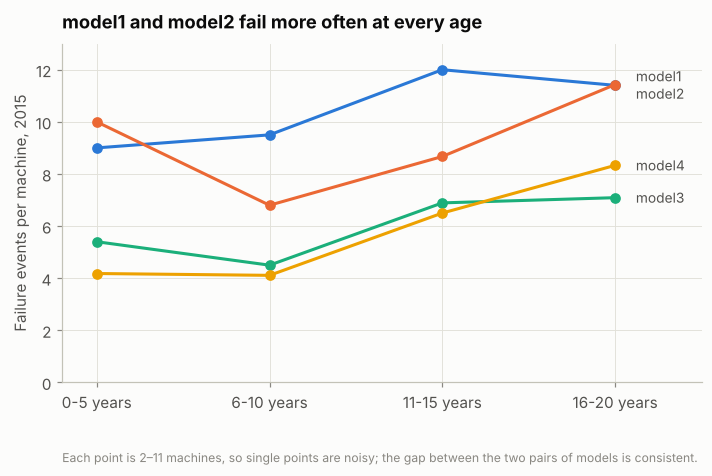

In [6]:
order = ["0-5", "6-10", "11-15", "16-20"]
fig, ax = plt.subplots(figsize=(7.5, 4))
for color, (m, g) in zip(SERIES, cross.groupby("model")):
    g = g.set_index("age_group").loc[order]
    ax.plot(range(4), g["events_per_machine"], color=color, marker="o", markersize=6)
    nudge = {"model1": 0.35, "model2": -0.35}.get(m, 0)
    ax.text(3.12, g["events_per_machine"].iloc[-1] + nudge, m, color=INK_2, va="center", fontsize=9)
ax.set_xticks(range(4), [f"{a} years" for a in order])
ax.set_xlim(-0.2, 3.5)
ax.set_ylim(0, 13)
ax.set_ylabel("Failure events per machine, 2015")
ax.set_title("model1 and model2 fail more often at every age")
ax.text(0, -0.2, "Each point is 2–11 machines, so single points are noisy; the gap between the two pairs of models is consistent.",
        transform=ax.transAxes, color=MUTED, fontsize=8, va="top")
pdm.save(fig, "q1_failures_by_model_age.png")
plt.show()

## 2. How reliable is each group? (Q2)

**MTBF** = operating hours ÷ failure events. Every machine runs the whole year (8,760 hours), so a model with 16 machines and 175 failures has an MTBF of 16 × 8,760 ÷ 175 = 801 hours (33 days). The SQL file also reports the median gap between consecutive failures as a cross-check.

In [7]:
mtbf = pdm.load_export("v_mtbf_by_model")
mtbf

,model,machines,failure_events,mtbf_hours,mtbf_days,gaps,mean_gap_hours,median_gap_hours
0,model1,16,175,801,33.4,159,768,720
1,model2,17,160,931,38.8,143,929,720
2,model3,35,212,1446,60.3,178,1265,1080
3,model4,32,172,1630,67.9,141,1470,1080


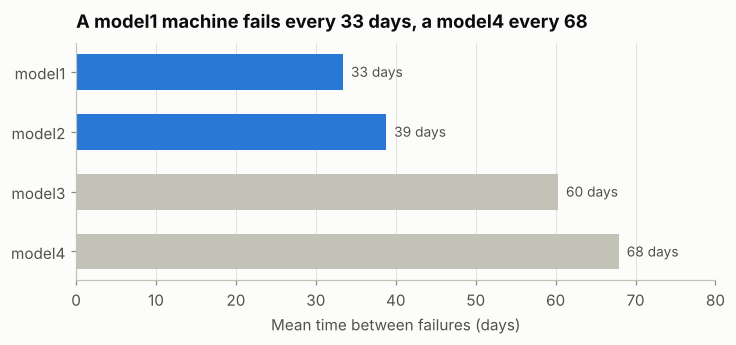

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
m = mtbf.sort_values("mtbf_days", ascending=False)
colors = [SERIES[0] if d < 45 else AXIS for d in m["mtbf_days"]]
ax.barh(m["model"], m["mtbf_days"], color=colors, height=0.6)
for y, d in enumerate(m["mtbf_days"]):
    ax.text(d + 1, y, f"{d:.0f} days", va="center", color=INK_2, fontsize=9)
ax.set_xlim(0, 80)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mean time between failures (days)")
ax.set_title("A model1 machine fails every 33 days, a model4 every 68")
pdm.save(fig, "q2_mtbf_by_model.png")
plt.show()

In [9]:
mc = pdm.load_export("v_mtbf_by_model_component")
mc.pivot(index="model", columns="comp", values="mtbf_days")

comp,comp1,comp2,comp3,comp4
model,,,,
model1,177.0,127.0,86.0,139.0
model2,207.0,151.0,98.0,183.0
model3,188.0,144.0,NaN,200.0
model4,191.0,141.0,NaN,299.0


**comp3 never fails on model3 or model4** (blank cells). On model1 and model2 it is the most frequent failure: one every 86–98 days per machine.

### Do older machines fail more often?

In [10]:
per_machine = pdm.load_export("v_failures_per_machine")
pdm.load_export("v_age_correlation")

,scope,machines,corr_age_failures,extra_failures_per_year
0,all machines,100,0.46,0.261
1,model4,32,0.54,0.251
2,model1,16,0.39,0.214
3,model3,35,0.47,0.178
4,model2,17,0.47,0.215


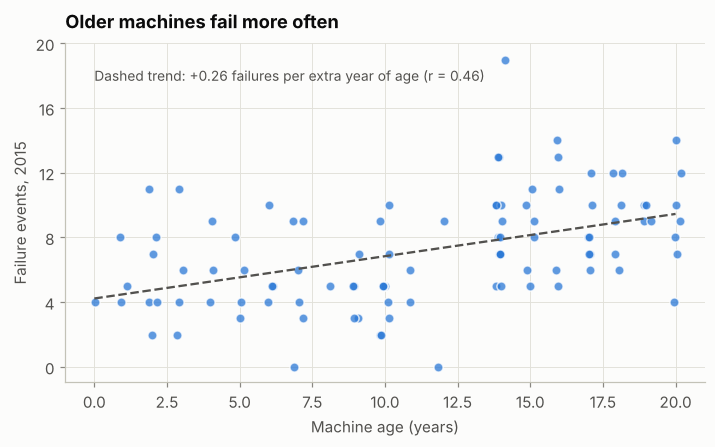

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
rng = np.random.default_rng(7)
x = per_machine["age"] + rng.uniform(-0.18, 0.18, len(per_machine))   # small jitter: machines share ages
ax.scatter(x, per_machine["failure_events"], s=36, color=SERIES[0], alpha=0.75,
           edgecolor="white", linewidth=1)
slope, intercept = np.polyfit(per_machine["age"], per_machine["failure_events"], 1)
xs = np.array([0, 20])
ax.plot(xs, intercept + slope * xs, color=INK_2, linewidth=1.5, linestyle="--")
r = per_machine[["age", "failure_events"]].corr().iloc[0, 1]
ax.text(0, 18, f"Dashed trend: +{slope:.2f} failures per extra year of age (r = {r:.2f})",
        color=INK_2, fontsize=9, va="center")
ax.set_xlim(-1, 21)
ax.set_yticks(range(0, 21, 4))
ax.set_xlabel("Machine age (years)")
ax.set_ylabel("Failure events, 2015")
ax.set_title("Older machines fail more often")
pdm.save(fig, "q2_age_vs_failures.png")
plt.show()

## 3. What happens before a failure? (preparing Q3)

The SQL analysis showed that error codes cluster in the 48 hours before failures. Now the sensors: voltage, rotation, pressure and vibration, read every hour.

In [12]:
raw = pdm.load_raw()
tel, failures = raw["telemetry"], raw["failures"]
events = pdm.failure_events(failures)
print(f"{len(tel):,} telemetry rows, {tel['machine_id'].nunique()} machines, "
      f"{tel['datetime'].min():%Y-%m-%d %H:%M} to {tel['datetime'].max():%Y-%m-%d %H:%M}")
tel[SENSORS].describe().round(1)

876,100 telemetry rows, 100 machines, 2015-01-01 06:00 to 2016-01-01 06:00


,volt,rotate,pressure,vibration
count,876100.0,876100.0,876100.0,876100.0
mean,170.8,446.6,100.9,40.4
std,15.5,52.7,11.0,5.4
min,97.3,138.4,51.2,14.9
25%,160.3,412.3,93.5,36.8
50%,170.6,447.6,100.4,40.2
75%,181.0,482.2,107.6,43.8
max,255.1,695.0,186.0,76.8


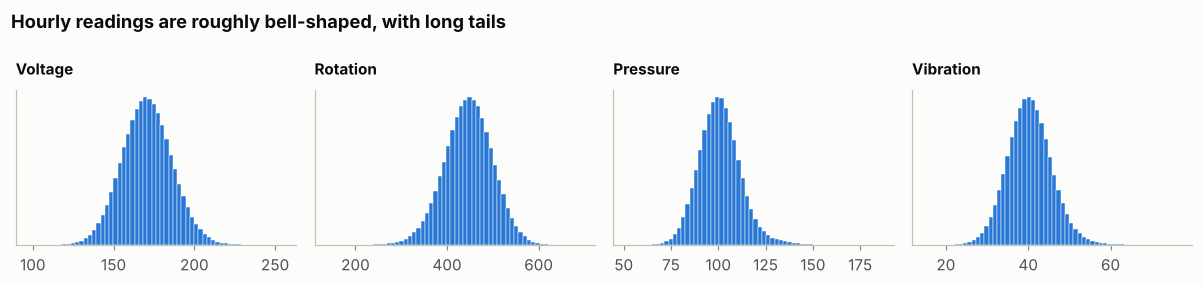

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(11, 2.6))
for ax, s in zip(axes, SENSORS):
    ax.hist(tel[s], bins=60, color=SERIES[0], edgecolor="white", linewidth=0.3)
    ax.set_title(SENSOR_LABEL[s], fontsize=10)
    ax.set_yticks([])
    ax.grid(False)
fig.suptitle("Hourly readings are roughly bell-shaped, with long tails", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
fig.tight_layout()
pdm.save(fig, "eda_sensor_distributions.png")
plt.show()

Hourly readings are noisy, so a single reading says little. Two steps make a change visible:

1. **Daily mean**: the rolling mean of the last 24 hourly readings.
2. **Each machine against its own normal**: the distance of that daily mean from the machine's baseline average, in baseline standard deviations (σ). The baseline is the first 30 days of the year, leaving out the 7 days before and 2 days after any failure. Machines differ, so a reading that is normal on one can be unusual on another.

These are the same two steps the control charts in notebook 02 use (`pdm.add_daily_mean`, `pdm.baseline_limits`, `pdm.add_z`).

In [14]:
tel = pdm.add_daily_mean(tel)
limits = pdm.baseline_limits(tel, events)
tel = pdm.add_z(tel, limits)
print(f"Baseline hours per machine: min {limits['baseline_hours'].min():.0f}, "
      f"median {limits['baseline_hours'].median():.0f}")
limits.head()

Baseline hours per machine: min 265, median 505


,machine_id,volt_mean,volt_sd,rotate_mean,rotate_sd,pressure_mean,pressure_sd,vibration_mean,vibration_sd,baseline_hours
0,1,172.901396,7.913396,452.788062,9.899432,99.734707,2.188667,39.899051,1.084398,576
1,2,172.158573,5.882159,452.644234,8.836796,101.739291,6.991682,40.808428,2.416034,697
2,3,171.414237,6.096014,441.441198,24.454073,99.778254,1.893123,40.255657,0.977125,504
3,4,172.187869,6.452676,449.305922,9.332121,99.733477,1.841105,40.223178,1.078518,481
4,5,169.261059,2.607510,433.949749,28.684925,100.452432,2.005669,40.935909,3.177788,481


For every component failure, take each sensor's distance from normal (σ) for each hour from 14 days before to 2 days after, then average across all failures of that component.

In [15]:
offsets = np.arange(-14 * 24, 2 * 24 + 1)
z_cols = [f"{s}_z" for s in SENSORS]
zt = tel.set_index(["machine_id", "datetime"])[z_cols]

rows = []
for f in failures.itertuples():
    idx = pd.MultiIndex.from_arrays([np.full(len(offsets), f.machine_id),
                                     f.datetime + pd.to_timedelta(offsets, unit="h")])
    vals = zt.reindex(idx).to_numpy()
    rows.append(pd.DataFrame(vals, columns=SENSORS).assign(comp=f.comp, hour=offsets))
profile = pd.concat(rows).groupby(["comp", "hour"])[SENSORS].mean()

# the sensor that moves most in the 48 hours before each component fails
window = profile[(profile.index.get_level_values("hour") >= -48) & (profile.index.get_level_values("hour") < 0)]
signature = window.abs().groupby("comp").mean().round(2)
signature["signature_sensor"] = signature.idxmax(axis=1)
signature

,volt,rotate,pressure,vibration,signature_sensor
comp,,,,,
comp1,4.59,0.45,0.22,0.29,volt
comp2,0.23,5.21,0.45,0.60,rotate
comp3,0.24,0.31,7.96,0.34,pressure
comp4,0.12,0.62,0.47,7.21,vibration


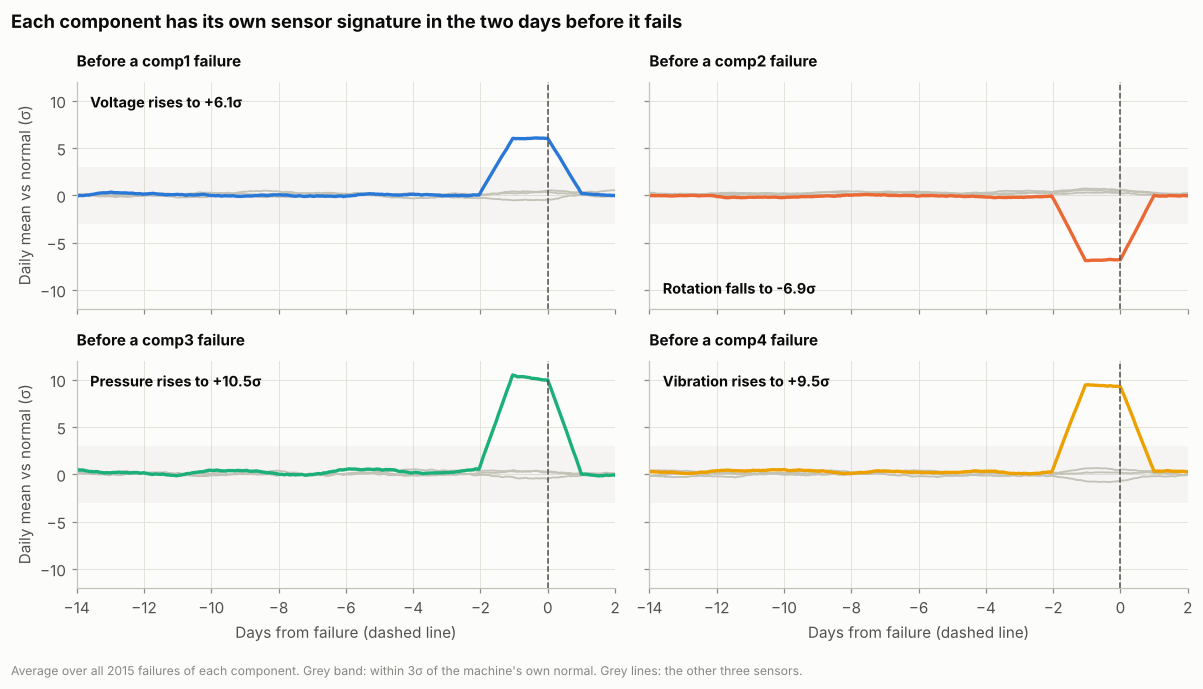

In [16]:
sensor_color = dict(zip(SENSORS, SERIES))
ylim = np.ceil(profile.abs().max().max()) + 1
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True, sharey=True)
for ax, comp_name in zip(axes.flat, COMPONENTS):
    p = profile.loc[comp_name]
    sig = signature.loc[comp_name, "signature_sensor"]
    for s in SENSORS:
        if s != sig:
            ax.plot(p.index / 24, p[s], color=AXIS, linewidth=1.2)
    ax.plot(p.index / 24, p[sig], color=sensor_color[sig], linewidth=2.2)
    peak = p[sig].loc[-48:-1]
    top = peak.loc[peak.abs().idxmax()]
    ax.text(-13.6, 0.82 * ylim * np.sign(top), f"{SENSOR_LABEL[sig]} {'falls' if top < 0 else 'rises'} to {top:+.1f}σ",
            color=INK, fontsize=9.5, fontweight="bold", va="center")
    ax.axvline(0, color=INK_2, linewidth=1, linestyle="--")
    ax.axhspan(-3, 3, color=AXIS, alpha=0.12, linewidth=0)
    ax.set_title(f"Before a {comp_name} failure", fontsize=10)
    ax.set_xlim(-14, 2)
    ax.set_ylim(-ylim, ylim)
for ax in axes[1]:
    ax.set_xlabel("Days from failure (dashed line)")
for ax in axes[:, 0]:
    ax.set_ylabel("Daily mean vs normal (σ)")
fig.suptitle("Each component has its own sensor signature in the two days before it fails",
             x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.text(0.01, 0.005, "Average over all 2015 failures of each component. Grey band: within 3σ of the machine's own normal. "
         "Grey lines: the other three sensors.", color=MUTED, fontsize=8)
fig.tight_layout(rect=(0, 0.03, 1, 1))
pdm.save(fig, "q3_sensor_signatures.png")
plt.show()

## Findings so far

- **Q1.** comp2 and comp1 cause 59% of component failures. model1 and model2 are a third of the fleet but cause 47% of failure events, and they fail more often at every age. comp3 only fails on these two models.
- **Q2.** MTBF is 33 days for model1 and 68 days for model4. Older machines fail more often too: about a quarter of a failure more per year of age (r = 0.46), and the link holds inside every model.
- **Q3 preview.** Each component has its own warning in the sensors: voltage rises before comp1 fails, rotation falls before comp2, pressure rises before comp3 and vibration rises before comp4. The daily mean starts to move two days before the failure and spends the last day 6–10σ away from normal. Ten days before, nothing is visible. So there is roughly **one to two days of notice**, not weeks.

Next: `02_control_charts.ipynb` turns this into control charts per machine.